# 04 · Explainability (SHAP)
Global: which features matter overall. Local: why *this* shipment got *this* prediction. The API turns local SHAP values into the top-3 human-readable reasons.

In [1]:
# Setup: make the project importable from the notebooks/ folder
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
os.environ.setdefault("ARRIVO_OFFLINE", "1")     # use cached/offline enrichment for reproducibility
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)

def show(path, width=11):
    """Display a saved figure inline."""
    img = plt.imread(path); h, w = img.shape[:2]
    fig, ax = plt.subplots(figsize=(width, width * h / w)); ax.imshow(img); ax.axis("off"); plt.show()

In [2]:
import joblib
from src import config
from src.data.load import load_canonical; from src.data.clean import clean; from src.data.enrich import enrich
from src.features.build_features import build_model_frames, feature_matrix
from src.explain.shap_utils import explain, top_reasons, group_contributions
canonical, source = load_canonical(); df, _ = clean(canonical)
_, _, test, _ = build_model_frames(enrich(df, live=(source != 'synthetic')))
X = feature_matrix(test)
eta_art, del_art = joblib.load(config.ETA_MODEL_FILE), joblib.load(config.DELAY_MODEL_FILE)
eta_c, eta_base, m1 = explain(eta_art['pipeline'], X, 'regression')
del_c, del_base, m2 = explain(del_art['pipeline'], X, 'classification')
print('explainers:', m1, '/', m2)

explainers: saabas / linear-exact


**Sanity check – additivity:** base value + sum of contributions must equal the model's prediction.

In [3]:
pred = eta_art['pipeline'].predict(X)
print('max |base + Σ SHAP − prediction| =', float(np.max(np.abs(eta_base + eta_c.sum(axis=1) - pred))))

max |base + Σ SHAP − prediction| = 3.126388037344441e-13


## Global explanations

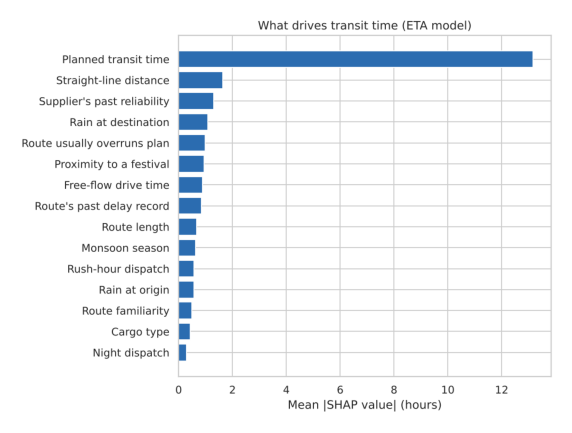

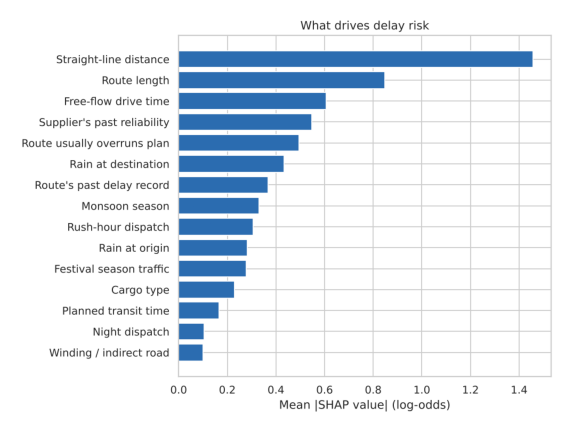

In [4]:
show(ROOT/'reports/figures/shap_eta_importance.png', 8); show(ROOT/'reports/figures/shap_delay_importance.png', 8)

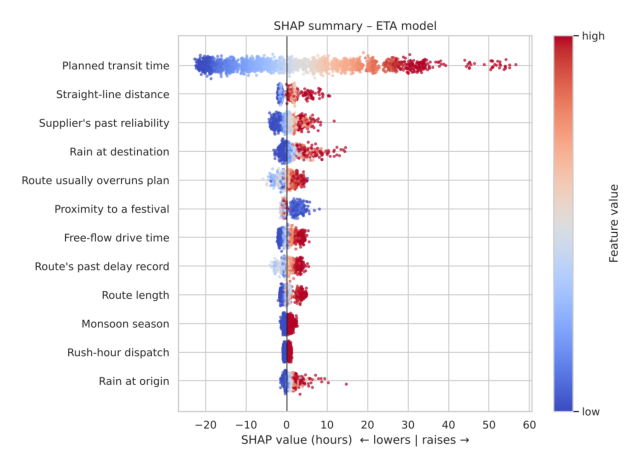

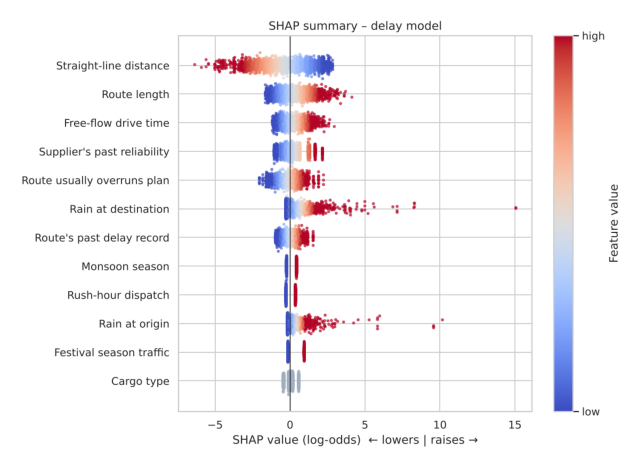

In [5]:
show(ROOT/'reports/figures/shap_eta_summary.png', 9); show(ROOT/'reports/figures/shap_delay_summary.png', 9)

Reading the summary plot: each dot is a shipment; red = high feature value. Red dots on the right for *Rain at destination* mean more rain → longer ETA / higher risk.

## Grouped importance (what managers see)
Correlated features (road km, straight-line km, drive time) share credit, so for reasons we add them into groups – allowed because SHAP values are additive.

In [6]:
grouped = del_c.apply(group_contributions, axis=1).abs().mean().sort_values(ascending=False)
grouped.round(3).to_frame('mean |SHAP| (delay model)')

,mean |SHAP| (delay model)
route_history,0.847
rain,0.618
supplier,0.547
dispatch_time,0.356
season,0.341
festival,0.320
cargo,0.229
schedule,0.197
terrain,0.147
regions,0.098


## Local explanations

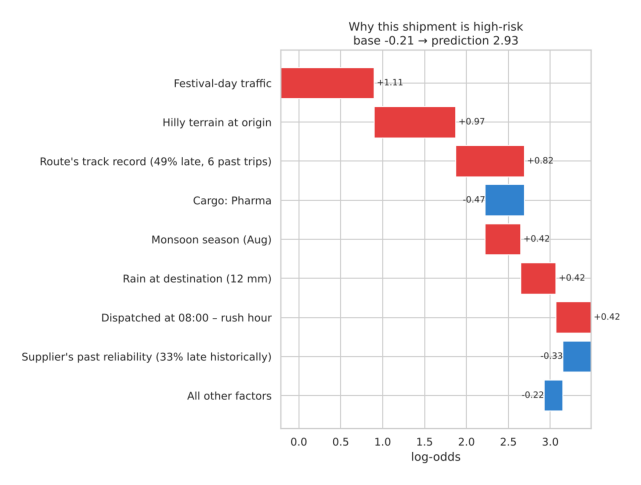

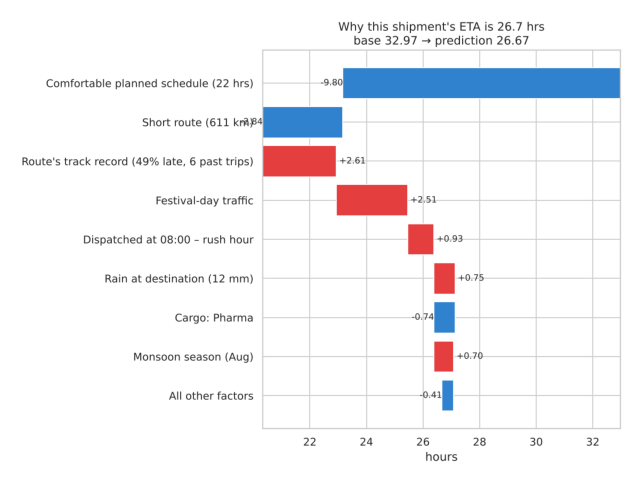

In [7]:
show(ROOT/'reports/figures/shap_delay_waterfall_example.png', 9); show(ROOT/'reports/figures/shap_eta_waterfall_example.png', 9)

In [8]:
proba = del_art['calibrated'].predict_proba(X)[:, 1]
for i in [int(np.argmax(proba)), int(np.argmin(np.abs(proba-0.5))), int(np.argmin(proba))]:
    idx = X.index[i]; r = test.loc[idx]
    print(f"{r.origin_city} → {r.destination_city} | {r.dispatch_time:%d %b %Y %H:%M} | risk {proba[i]:.0%} | actually late: {bool(r.is_delayed)}")
    for reason in top_reasons(eta_c.loc[idx], del_c.loc[idx], X.loc[idx], prefer='raise' if proba[i] >= 0.35 else 'lower'):
        print('   •', reason['text'], '–', reason['risk_direction'])

Kochi → Mumbai | 31 Jul 2025 06:17 | risk 100% | actually late: True
   • Heavy rain at destination (236 mm) (+15.2 hrs) – raises risk
   • Monsoon season (Jul) (+1.1 hrs) – raises risk
   • Supplier's past reliability (42% late historically) (+0.9 hrs) – raises risk
Bhiwandi → Gurugram | 15 Oct 2025 16:55 | risk 50% | actually late: False
   • Festival-season traffic (5 days from a major festival) (-1.0 hrs) – raises risk
   • Route's track record (41% late, 11 past trips) (+1.0 hrs) – raises risk
   • Supplier's past reliability (46% late historically) (+1.0 hrs) – raises risk
Bhiwandi → Pune | 17 Nov 2025 16:02 | risk 0% | actually late: False
   • Route's track record (15% late, 43 past trips) (-1.2 hrs) – lowers risk
   • Supplier's past reliability (26% late historically) (-1.4 hrs) – lowers risk
   • Comfortable planned schedule (7 hrs) – lowers risk


## End-to-end: the same predictor the API uses

In [9]:
from src.models.predict import ArrivoPredictor
import json
p = ArrivoPredictor()
print(json.dumps(p.predict_one({'origin_city':'Delhi','destination_city':'Shimla','dispatch_time':'2025-08-10T09:00','vehicle_type':'17 FT Container','material_type':'FMCG','supplier_id':'SUP003','dest_rain_mm':80}), indent=1, default=str)[:1500])

{
 "shipment_id": "REQ-1",
 "origin_city": "Delhi",
 "destination_city": "Shimla",
 "dispatch_time": "2025-08-10T09:00:00",
 "eta_hours": 19.08,
 "expected_arrival": "2025-08-11T04:05",
 "planned_hours": 12.42,
 "planned_arrival": "2025-08-10T21:24",
 "expected_delay_hours": 6.67,
 "delay_probability": 0.9979,
 "risk_level": "High",
 "flagged_late": true,
 "top_reasons": [
  {
   "factor": "rain",
   "text": "Rain at origin (22 mm) and destination (80 mm) (+7.5 hrs)",
   "eta_impact_hours": 7.45,
   "risk_direction": "raises risk",
   "risk_impact": 5.578
  },
  {
   "factor": "supplier",
   "text": "Supplier's past reliability (58% late historically) (+1.2 hrs)",
   "eta_impact_hours": 1.21,
   "risk_direction": "raises risk",
   "risk_impact": 1.313
  },
  {
   "factor": "terrain",
   "text": "Hilly terrain at destination (+0.2 hrs)",
   "eta_impact_hours": 0.19,
   "risk_direction": "raises risk",
   "risk_impact": 0.814
  }
 ],
 "route": {
  "origin": [
   28.61,
   77.21
  ],
  "d